In [1]:
# Check Python version
!python --version

Python 3.13.9


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import os

In [3]:
import pickle
import itertools
from collections import Counter, defaultdict

from wordcloud import WordCloud

In [30]:
from matplotlib.patches import FancyBboxPatch
from matplotlib.patches import FancyArrowPatch
import textwrap

In [4]:
seed = 42

os.environ['CUDA_VISIBLE_DEVICES'] = '0'
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)

In [5]:
df_name = 'reuters'
df_text_name = df_name + '_text'

df = pd.read_parquet(f'data/processed/parquet/{df_text_name}.parquet')
docs = df['text'].tolist()

len(docs)

10252

In [7]:
# Load topics dictionary
# Format expected: {topic_id: [('word1', 0.9), ('word2', 0.8), ...]}
# dict_path = f"{df_name}/{df_name}_topics_dict.pkl"

model_name = 'bertopic'
glob_path = f"saved/{df_name}_{model_name}"
dict_path = f"{glob_path}/{df_name}_topics_dict.pkl"

with open(dict_path, "rb") as f:
    topics_dict = pickle.load(f)

topics_dict

{-1: [('securities', np.float32(0.79453844)),
  ('shares', np.float32(0.7723867)),
  ('shareholders', np.float32(0.7537606)),
  ('stock', np.float32(0.75257593)),
  ('investor', np.float32(0.7444678)),
  ('financial', np.float32(0.7229292)),
  ('investment', np.float32(0.72113925)),
  ('ltd', np.float32(0.69589525)),
  ('industries', np.float32(0.6931855)),
  ('merger', np.float32(0.69289327))],
 0: [('stock', np.float32(0.7659404)),
  ('dividend', np.float32(0.732034)),
  ('company', np.float32(0.7031527)),
  ('funds', np.float32(0.69408673)),
  ('cash', np.float32(0.678873)),
  ('payable', np.float32(0.63900334)),
  ('insurance', np.float32(0.6320856)),
  ('payment', np.float32(0.6197591)),
  ('amount', np.float32(0.61973417)),
  ('semi-annual', np.float32(0.6147163))],
 1: [('dividends', np.float32(0.83400905)),
  ('investments', np.float32(0.73762167)),
  ('profit', np.float32(0.72591627)),
  ('pre-tax', np.float32(0.7103379)),
  ('after-tax', np.float32(0.70690286)),
  ('accountin

In [8]:
with open(f"{glob_path}/{df_name}_topics_word_list.json", "r") as f:
    topics_word_list = json.load(f)

topics_word_list[:5]

['stock dividend company funds cash payable insurance payment amount semi-annual',
 'dividends investments profit pre-tax after-tax accounting write-off pretax credit nonrecurring',
 'investment income fiscal credit business ltd tax credits shrs billion',
 'acquisitions equity revenues earnings business fiscal analysts costs auditors westinghouse',
 'bankamerica chargeoffs fdic mortgage loans bancshares loan financial banking brokerage']

In [9]:
def show_document_with_topics(doc_id):
    print("Document ID:", doc_id)
    print(docs[doc_id])

    topics = final_topics_for_all[doc_id]
    print("Topics in this document:")
    
    for topic_id, prob in topics:
        print(f"  Topic {topic_id}: {prob}")
        print(f"  Top words: {', '.join(word for word, _ in topics_dict.get(topic_id, []))}")

In [10]:
topic_frequencies = Counter()

for topic in topics_word_list:
    # Split the string into words and convert to a set to remove duplicates within the same topic
    unique_words_in_topic = set(topic.split())
    topic_frequencies.update(unique_words_in_topic)

In [11]:
print("--- BROADEST WORDS (Appearing in the most topics) ---")
# .most_common() automatically sorts from highest to lowest
for word, count in topic_frequencies.most_common(20):
    print(f"{word}: {count} topics")

--- BROADEST WORDS (Appearing in the most topics) ---
shares: 16 topics
credit: 13 topics
profit: 13 topics
stock: 11 topics
dividend: 11 topics
tax: 11 topics
economic: 11 topics
sales: 11 topics
fiscal: 10 topics
earnings: 10 topics
traders: 10 topics
shrs: 9 topics
liquidity: 9 topics
transaction: 9 topics
inflation: 9 topics
trade: 9 topics
economy: 9 topics
treasury: 8 topics
economists: 8 topics
exports: 8 topics


In [12]:
print("\n--- MOST SPECIFIC WORDS (Appearing in the fewest topics) ---")
# slice the most_common list backwards to get the least common
least_common = topic_frequencies.most_common()[:-21:-1] 
for word, count in least_common:
    print(f"{word}: {count} topics")


--- MOST SPECIFIC WORDS (Appearing in the fewest topics) ---
qtly: 1 topics
qtrly: 1 topics
freeport-mcmoran: 1 topics
advisers: 1 topics
greenmail: 1 topics
financially: 1 topics
conglomerate: 1 topics
gencorp: 1 topics
nyse: 1 topics
levitt: 1 topics
marketable: 1 topics
overfunded: 1 topics
waiver: 1 topics
amortisation: 1 topics
indebtedness: 1 topics
airbus: 1 topics
deflationary: 1 topics
superfund: 1 topics
stockbroking: 1 topics
diversifying: 1 topics


In [13]:
co_occurrences = Counter()

# intra-topic keyword orthogonality 

for topic in topics_word_list:
    # sort the words first
    words = sorted(set(topic.split()))
    
    # Generate all possible 2-word combinations in this topic
    pairs = itertools.combinations(words, 2)
    co_occurrences.update(pairs)

print("\n--- TOP CO-OCCURRENCES (Words appearing together) ---")
for pair, count in co_occurrences.most_common(20):
    print(f"{pair[0]} & {pair[1]}: {count} times")


--- TOP CO-OCCURRENCES (Words appearing together) ---
dividend & stock: 6 times
sales & shrs: 6 times
shares & stock: 6 times
profit & sales: 6 times
tariffs & trade: 6 times
credit & profit: 5 times
pretax & profit: 5 times
billion & shrs: 5 times
credit & tax: 5 times
income & tax: 5 times
economic & monetary: 5 times
economic & inflation: 5 times
protectionist & tariffs: 5 times
dividend & profit: 5 times
economic & economy: 5 times
profit & profits: 5 times
credit & investment: 4 times
fiscal & income: 4 times
investment & tax: 4 times
acquisitions & earnings: 4 times


In [14]:
final_topics_path = f"{glob_path}/{df_name}_final_topics.pkl"


with open(final_topics_path, "rb") as f:
    final_topics_for_all = pickle.load(f)

final_topics_for_all[:3]

[[(np.int64(53), np.float64(0.024370037917817635)),
  (np.int64(111), np.float64(0.02148584172121984))],
 [(np.int64(105), np.float64(0.05632981092360255)),
  (np.int64(109), np.float64(0.04244865484017223)),
  (np.int64(108), np.float64(0.036039737669515653))],
 [(np.int64(10), np.float64(0.17537192806387178)),
  (np.int64(55), np.float64(0.12423427750697694)),
  (np.int64(111), np.float64(0.04342061048548736)),
  (np.int64(99), np.float64(0.04013222223656901))]]

In [15]:
topic_frequencies = Counter()
co_occurrences = Counter()

In [16]:
for doc in final_topics_for_all:
    # Extract ONLY the topic ID (index 0 of the tuple) and convert to standard int
    # Use a set to ensure we only count a topic once per document
    topics_in_doc = set(int(topic_tuple[0]) for topic_tuple in doc)
    
    # Update how many documents each topic appears in
    topic_frequencies.update(topics_in_doc)
    
    # --- Co-occurrence logic ---
    # Sort the topics so pair (A, B) is identical to (B, A)
    sorted_topics = sorted(list(topics_in_doc))
    # Generate 2-topic combinations for this document
    pairs = itertools.combinations(sorted_topics, 2)
    co_occurrences.update(pairs)

In [17]:
print("--- TOPICS IN THE MOST DOCUMENTS ---")
for topic_id, count in topic_frequencies.most_common(10):
    print(f"Topic {topic_id}: {count} documents")

print("\n--- TOPICS IN THE FEWEST DOCUMENTS ---")
least_common = topic_frequencies.most_common()[:-11:-1] 
for topic_id, count in least_common:
    print(f"Topic {topic_id}: {count} documents")

print("\n--- TOP CO-OCCURRING TOPICS ---")
for pair, count in co_occurrences.most_common(10):
    print(f"Topic {pair[0]} & Topic {pair[1]}: {count} times")

--- TOPICS IN THE MOST DOCUMENTS ---
Topic 111: 4805 documents
Topic 51: 1155 documents
Topic 62: 1064 documents
Topic 105: 940 documents
Topic 2: 741 documents
Topic 7: 727 documents
Topic 78: 670 documents
Topic 109: 655 documents
Topic 83: 603 documents
Topic 0: 569 documents

--- TOPICS IN THE FEWEST DOCUMENTS ---
Topic 1: 6 documents
Topic 36: 17 documents
Topic 71: 21 documents
Topic 98: 24 documents
Topic 16: 26 documents
Topic 121: 27 documents
Topic 90: 28 documents
Topic 49: 31 documents
Topic 73: 31 documents
Topic 113: 32 documents

--- TOP CO-OCCURRING TOPICS ---
Topic 51 & Topic 111: 1009 times
Topic 105 & Topic 111: 651 times
Topic 0 & Topic 83: 487 times
Topic 0 & Topic 127: 487 times
Topic 83 & Topic 127: 450 times
Topic 2 & Topic 62: 426 times
Topic 109 & Topic 111: 344 times
Topic 0 & Topic 7: 306 times
Topic 7 & Topic 83: 298 times
Topic 7 & Topic 127: 293 times


In [18]:
topics_dict[51]

[('midsession', np.float32(0.68889344)),
 ('bills', np.float32(0.6714357)),
 ('shortfall', np.float32(0.66626704)),
 ('bill', np.float32(0.66028374)),
 ('revised', np.float32(0.6599482)),
 ('amounts', np.float32(0.6586934)),
 ('treasury', np.float32(0.6551271)),
 ('paye', np.float32(0.6548821)),
 ('liquidity', np.float32(0.65145546)),
 ('bank', np.float32(0.64579487))]

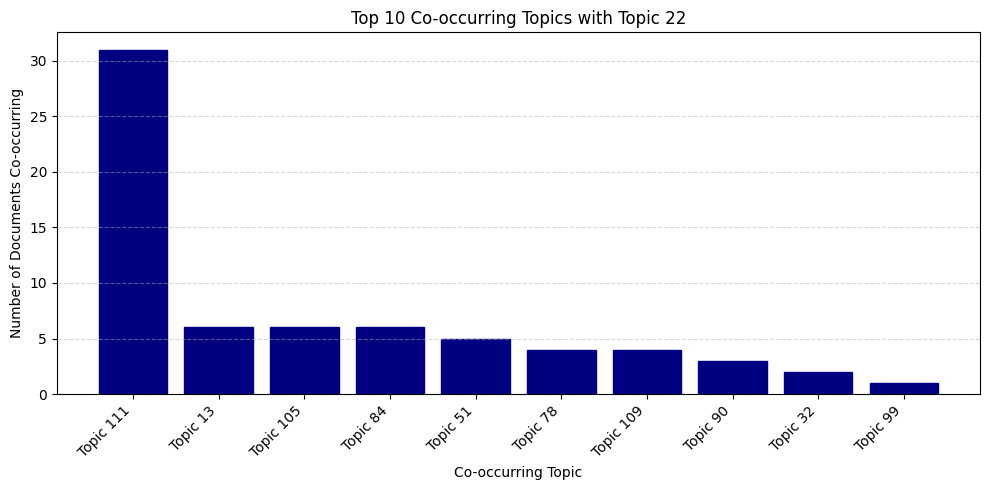

In [19]:
selected_topics = [22]
top_n = 10

for selected_topic in selected_topics:
    co_topics = []

    # Find all co-occurrence pairs involving the selected topic
    for (topic_a, topic_b), count in co_occurrences.items():
        if topic_a == selected_topic:
            co_topics.append((topic_b, count))
        elif topic_b == selected_topic:
            co_topics.append((topic_a, count))

    # Sort by co-occurrence count and keep top N
    co_topics = sorted(co_topics, key=lambda x: x[1], reverse=True)[:top_n]

    # Skip if topic has no co-occurrences
    if not co_topics:
        print(f"Topic {selected_topic} has no co-occurring topics.")
        continue

    labels = [f"Topic {topic_id}" for topic_id, count in co_topics]
    counts = [count for topic_id, count in co_topics]

    plt.figure(figsize=(10, 5))
    plt.bar(labels, counts, color="navy", edgecolor="navy")

    plt.title(f"Top {top_n} Co-occurring Topics with Topic {selected_topic}")
    plt.xlabel("Co-occurring Topic")
    plt.ylabel("Number of Documents Co-occurring")
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

In [20]:
import plotly.graph_objects as go

def get_top_cooccurring(topic_id, co_occurrences, top_n=10):
    co_topics = []

    for (topic_a, topic_b), count in co_occurrences.items():
        if topic_a == topic_id:
            co_topics.append((topic_b, count))
        elif topic_b == topic_id:
            co_topics.append((topic_a, count))

    co_topics = sorted(co_topics, key=lambda x: x[1], reverse=True)
    return co_topics[:top_n]


def build_sankey_chain(topic_frequencies, co_occurrences, top_n=10, levels=4):
    # Start from the most common topic
    current_topic = topic_frequencies.most_common(1)[0][0]

    labels = []
    label_to_idx = {}
    sources = []
    targets = []
    values = []

    def add_node(topic_id, level):
        label = f"L{level}: Topic {topic_id}"
        if label not in label_to_idx:
            label_to_idx[label] = len(labels)
            labels.append(label)
        return label_to_idx[label]

    for level in range(1, levels):
        source_idx = add_node(current_topic, level)

        top_co_topics = get_top_cooccurring(
            current_topic,
            co_occurrences,
            top_n=top_n
        )

        if not top_co_topics:
            break

        for co_topic, count in top_co_topics:
            target_idx = add_node(co_topic, level + 1)
            sources.append(source_idx)
            targets.append(target_idx)
            values.append(count)

        # Continue from the most common topic among the correlated ones
        current_topic = max(
            [topic for topic, count in top_co_topics],
            key=lambda topic: topic_frequencies[topic]
        )

    return labels, sources, targets, values


labels, sources, targets, values = build_sankey_chain(
    topic_frequencies=topic_frequencies,
    co_occurrences=co_occurrences,
    top_n=10,
    levels=4
)

fig = go.Figure(
    data=[
        go.Sankey(
            node=dict(
                pad=20,
                thickness=18,
                line=dict(color="black", width=0.5),
                label=labels
            ),
            link=dict(
                source=sources,
                target=targets,
                value=values
            )
        )
    ]
)

fig.update_layout(
    title_text="Topic Co-occurrence Sankey Diagram",
    font_size=11,
    width=1100,
    height=700
)

fig.show()

In [21]:
def get_top_cooccurring(topic_id, co_occurrences, top_n=10, exclude=None):
    if exclude is None:
        exclude = set()

    co_topics = []

    for (topic_a, topic_b), count in co_occurrences.items():
        if topic_a == topic_id and topic_b not in exclude:
            co_topics.append((topic_b, count))
        elif topic_b == topic_id and topic_a not in exclude:
            co_topics.append((topic_a, count))

    co_topics = sorted(co_topics, key=lambda x: x[1], reverse=True)
    return co_topics[:top_n]

In [22]:
def format_topic_label(topic_id, topics_dict=None, n_words=3):
    if topics_dict is None:
        return f"Topic {topic_id}"

    words = topics_dict.get(int(topic_id), [])
    top_words = [word for word, prob in words[:n_words]]

    if top_words:
        return f"Topic {topic_id}\n" + ", ".join(top_words)

    return f"Topic {topic_id}"

In [23]:
import plotly.graph_objects as go

def build_sankey_chain(
    topic_frequencies,
    co_occurrences,
    topics_dict=None,
    top_n=10,
    levels=4,
    n_words=5
):
    current_topic = topic_frequencies.most_common(1)[0][0]

    labels = []
    label_to_idx = {}
    sources = []
    targets = []
    values = []

    expanded_topics = set()

    def add_node(topic_id, level):
        # if topics_dict is not None:
        #     topic_label = format_topic_label(
        #         topic_id,
        #         topics_dict,
        #         n_words=n_words,
        #         line_break="<br>"
        #     )
        # else:
        topic_label = f"Topic {topic_id}"

        label = f"L{level}: {topic_label}"

        if label not in label_to_idx:
            label_to_idx[label] = len(labels)
            labels.append(label)

        return label_to_idx[label]

    for level in range(1, levels):
        source_idx = add_node(current_topic, level)

        expanded_topics.add(current_topic)

        top_co_topics = get_top_cooccurring(
            topic_id=current_topic,
            co_occurrences=co_occurrences,
            top_n=top_n
        )

        if not top_co_topics:
            break

        for co_topic, count in top_co_topics:
            target_idx = add_node(co_topic, level + 1)
            sources.append(source_idx)
            targets.append(target_idx)
            values.append(count)

        expandable_candidates = [
            (topic, count)
            for topic, count in top_co_topics
            if topic not in expanded_topics
        ]

        if not expandable_candidates:
            break

        current_topic = max(
            expandable_candidates,
            key=lambda x: x[1]
        )[0]

    return labels, sources, targets, values

In [24]:
labels, sources, targets, values = build_sankey_chain(
    topic_frequencies=topic_frequencies,
    co_occurrences=co_occurrences,
    topics_dict=topics_dict,
    top_n=10,
    levels=4,
    n_words=5
)

fig = go.Figure(
    data=[
        go.Sankey(
            node=dict(
                pad=20,
                thickness=20,
                line=dict(color="black", width=0.5),
                label=labels
            ),
            link=dict(
                source=sources,
                target=targets,
                value=values
            )
        )
    ]
)

fig.update_layout(
    title_text="Topic Co-occurrence Sankey Diagram",
    font_size=11,
    width=1100,
    height=700
)

fig.show()

In [25]:
import networkx as nx

def build_topic_flow_graph(
    topic_frequencies,
    co_occurrences,
    topics_dict=None,
    start_topic_id=None,
    top_n=10,
    levels=4,
    n_words=3
):
    if start_topic_id is None:
        current_topic = topic_frequencies.most_common(1)[0][0]
    else:
        current_topic = int(start_topic_id)

    G = nx.DiGraph()

    considered_topics = set()

    for level in range(1, levels):
        source_node = (level, current_topic)

        G.add_node(
            source_node,
            label=format_topic_label(current_topic, topics_dict, n_words),
            level=level
        )

        considered_topics.add(current_topic)

        top_co_topics = get_top_cooccurring(
            topic_id=current_topic,
            co_occurrences=co_occurrences,
            top_n=top_n,
            exclude=considered_topics
        )

        if not top_co_topics:
            break

        for co_topic, count in top_co_topics:
            target_node = (level + 1, co_topic)

            G.add_node(
                target_node,
                label=format_topic_label(co_topic, topics_dict, n_words),
                level=level + 1
            )

            G.add_edge(source_node, target_node, weight=count)

            # Mark as considered immediately, so it cannot appear again later
            considered_topics.add(co_topic)

        # Since top_co_topics is sorted by count descending,
        # the first one has the highest co-occurrence count.
        current_topic = top_co_topics[0][0]

    return G

In [26]:
start_topic_id = 10

In [28]:
# G = build_topic_flow_graph(
#     topic_frequencies=topic_frequencies,
#     co_occurrences=co_occurrences,
#     topics_dict=topics_dict,
#     start_topic_id=start_topic_id,
#     top_n=10,
#     levels=4,
#     n_words=3
# )

# pos = {}

# levels_dict = {}
# for node, attrs in G.nodes(data=True):
#     level = attrs["level"]
#     levels_dict.setdefault(level, []).append(node)

# for level, nodes in levels_dict.items():
#     n = len(nodes)
#     for i, node in enumerate(nodes):
#         x = level
#         y = i - (n - 1) / 2
#         pos[node] = (x, -y)

# labels = nx.get_node_attributes(G, "label")
# weights = nx.get_edge_attributes(G, "weight")

# max_weight = max(weights.values()) if weights else 1

# edge_widths = [
#     0.5 + 4 * (weights[edge] / max_weight)
#     for edge in G.edges()
# ]

# plt.figure(figsize=(18, 10))

# nx.draw_networkx_edges(
#     G,
#     pos,
#     width=edge_widths,
#     alpha=0.5,
#     arrows=True,
#     arrowsize=15,
#     edge_color="gray"
# )

# nx.draw_networkx_nodes(
#     G,
#     pos,
#     node_size=3500,
#     node_color="lightblue",
#     edgecolors="navy",
#     linewidths=1.2
# )

# nx.draw_networkx_labels(
#     G,
#     pos,
#     labels=labels,
#     font_size=12,
#     font_weight="bold"
# )

# edge_labels = {
#     edge: str(weight)
#     for edge, weight in weights.items()
# }

# nx.draw_networkx_edge_labels(
#     G,
#     pos,
#     edge_labels=edge_labels,
#     font_size=12
# )

# #plt.title("Static Topic Co-occurrence Flow Diagram")
# plt.axis("off")
# plt.tight_layout()
# plt.savefig(
#     "topic_flow_graph.pdf",
#     format="pdf",
#     bbox_inches="tight"
# )
# plt.show()

C:\Users\zheng\AppData\Local\Temp\ipykernel_46652\1490843985.py:161: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



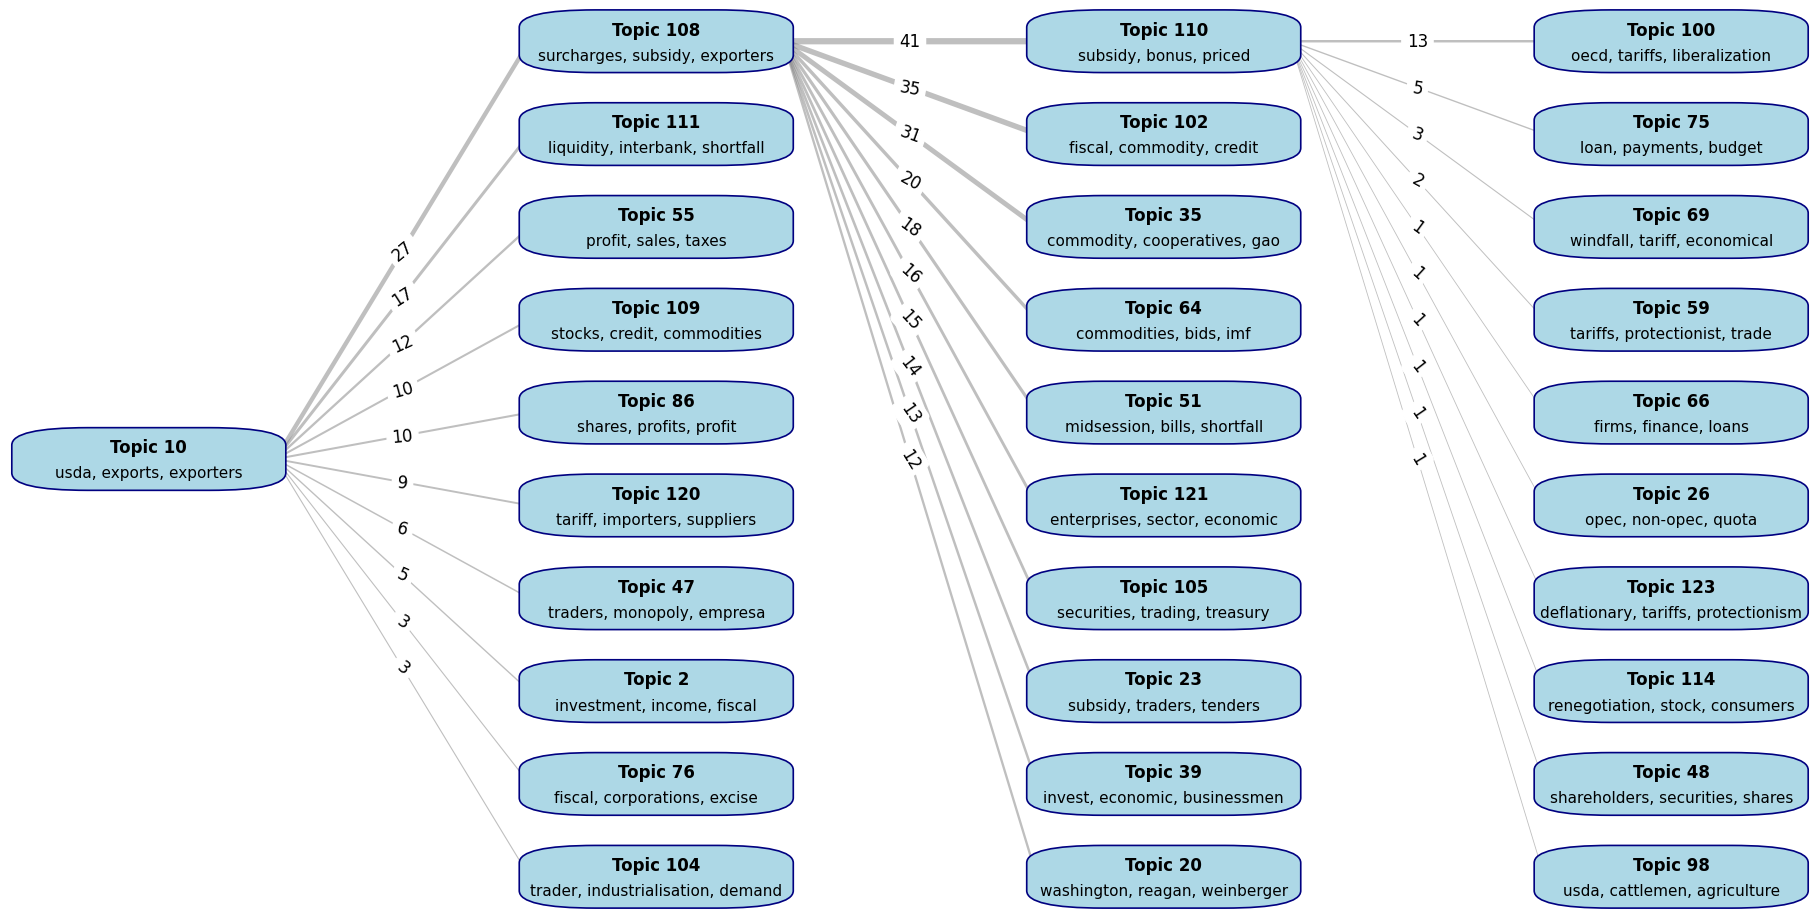

In [31]:
G = build_topic_flow_graph(
    topic_frequencies=topic_frequencies,
    co_occurrences=co_occurrences,
    topics_dict=topics_dict,
    start_topic_id=start_topic_id,
    top_n=10,
    levels=4,
    n_words=3
)

pos = {}

levels_dict = {}
for node, attrs in G.nodes(data=True):
    level = attrs["level"]
    levels_dict.setdefault(level, []).append(node)

for level, nodes in levels_dict.items():
    n = len(nodes)
    for i, node in enumerate(nodes):
        x = level
        y = (i - (n - 1) / 2) * 0.8
        pos[node] = (x, -y)

labels = nx.get_node_attributes(G, "label")
weights = nx.get_edge_attributes(G, "weight")

max_weight = max(weights.values()) if weights else 1

edge_widths = [
    0.5 + 4 * (weights[edge] / max_weight)
    for edge in G.edges()
]

plt.figure(figsize=(18, 9))

ax = plt.gca()

# Dimensions of the rectangular nodes
box_width = 0.5
box_height = 0.5

for u, v in G.edges():

    x1, y1 = pos[u]
    x2, y2 = pos[v]

    weight = weights[(u, v)]

    width = 0.5 + 4 * (weight / max_weight)

    # Starting point: right border of the source rectangle
    start = (
        x1 + box_width / 2,
        y1
    )

    # Ending point: left border of the target rectangle
    end = (
        x2 - box_width / 2,
        y2
    )

    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="-",
        mutation_scale=12,
        linewidth=width,
        color="gray",
        alpha=0.5,
        shrinkA=0,
        shrinkB=0,
        zorder=1
    )

    ax.add_patch(arrow)



for node, (x, y) in pos.items():

    label = labels[node]

    # Separate topic ID from keywords
    parts = label.split("\n", 1)

    topic_id = parts[0]
    keywords = parts[1] if len(parts) > 1 else ""

    # Wrap keywords to fit inside the rectangle
    keywords = textwrap.fill(
        keywords,
        width=37,
        break_long_words=False
    )

    # Draw rounded rectangle
    rectangle = FancyBboxPatch(
        (x - box_width / 2, y - box_height / 2),
        box_width,
        box_height,
        boxstyle="round,pad=0.02,rounding_size=0.15",
        facecolor="lightblue",
        edgecolor="navy",
        linewidth=1.2,
        zorder=3
    )

    ax.add_patch(rectangle)

    # Topic ID in bold
    ax.text(
        x,
        y + 0.1,
        topic_id,
        fontsize=12,
        fontweight="bold",
        ha="center",
        va="center",
        zorder=4
    )

    # Keywords in normal font
    ax.text(
        x,
        y - 0.12,
        keywords,
        fontsize=11,
        fontweight="normal",
        ha="center",
        va="center",
        linespacing=1.1,
        zorder=4
    )


edge_labels = {
    edge: str(weight)
    for edge, weight in weights.items()
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=12
)

#plt.title("Static Topic Co-occurrence Flow Diagram")
plt.axis("off")

plt.margins(0.001)

plt.subplots_adjust(
    left=0,
    right=1,
    top=1,
    bottom=0
)
plt.tight_layout()
plt.savefig(
    "flow_cooccurrence.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0
)
plt.show()

In [32]:
def get_ordered_topics(doc):
    """
    Extract topic ids from one document.
    Assumes doc is already ordered by relevance:
    [(topic_id, prob), (topic_id, prob), ...]
    """
    return [int(topic_id) for topic_id, prob in doc]

In [33]:
def format_topic_label(topic_id, topics_dict=None, n_words=3):
    if topics_dict is None:
        return f"Topic {topic_id}"

    words = topics_dict.get(int(topic_id), [])
    top_words = [word for word, prob in words[:n_words]]

    if top_words:
        return f"Topic {topic_id}\n" + ", ".join(top_words)

    return f"Topic {topic_id}"

In [34]:
def print_matching_docs(path, doc_indices):
    path_text = " -> ".join(f"Topic {topic_id}" for topic_id in path)
    docs_text = ", ".join(f"Doc {doc_idx}" for doc_idx in doc_indices)

    print(f"\nPath: {path_text}")
    print(f"Matching documents: {len(doc_indices)}")

    if docs_text:
        print(docs_text)
    else:
        print("No matching documents")

In [35]:
def build_ranked_topic_graph(
    final_topics_for_all,
    start_topic_id,
    topics_dict=None,
    top_n=10,
    levels=4,
    n_words=3,
    print_docs=True
):
    start_topic_id = int(start_topic_id)

    ordered_docs = [
        get_ordered_topics(doc)
        for doc in final_topics_for_all
    ]

    root_doc_indices = [
        i for i, topics in enumerate(ordered_docs)
        if len(topics) > 0 and topics[0] == start_topic_id
    ]

    G = nx.DiGraph()

    current_docs = root_doc_indices
    current_path = (start_topic_id,)

    root_node = (1, current_path)

    G.add_node(
        root_node,
        label=format_topic_label(start_topic_id, topics_dict, n_words),
        level=1,
        doc_count=len(root_doc_indices)
    )

    if print_docs:
        print_matching_docs(current_path, current_docs)

    current_node = root_node
    considered_topics = set([start_topic_id])

    for level in range(2, levels + 1):
        topic_counts = Counter()

        for doc_idx in current_docs:
            topics = ordered_docs[doc_idx]

            if len(topics) >= level:
                candidate_topic = topics[level - 1]

                if candidate_topic not in considered_topics:
                    topic_counts[candidate_topic] += 1

        if not topic_counts:
            break

        top_topics = topic_counts.most_common(top_n)

        child_nodes = []

        print(f"\n--- Level {level}: top {top_n} subnodes ---")

        for topic_id, count in top_topics:
            child_path = current_path + (topic_id,)

            child_doc_indices = [
                doc_idx for doc_idx in current_docs
                if len(ordered_docs[doc_idx]) >= level
                and tuple(ordered_docs[doc_idx][:level]) == child_path
            ]

            child_node = (level, child_path)

            G.add_node(
                child_node,
                label=format_topic_label(topic_id, topics_dict, n_words),
                level=level,
                doc_count=len(child_doc_indices)
            )

            G.add_edge(
                current_node,
                child_node,
                weight=count
            )

            child_nodes.append(
                (child_node, topic_id, count, child_doc_indices, child_path)
            )

            considered_topics.add(topic_id)

            if print_docs:
                print_matching_docs(child_path, child_doc_indices)

        next_child_node, next_topic, next_count, next_docs, next_path = child_nodes[0]

        if print_docs:
            next_path_text = " -> ".join(f"Topic {topic_id}" for topic_id in next_path)
            print(f"\nNext expanded path: {next_path_text}")
            print(f"Chosen because it has the highest count at level {level}: {next_count}")

        current_node = next_child_node
        current_docs = next_docs
        current_path = next_path

    return G

In [36]:
def display_ranked_topic_graph(start_topic_id, n_words=3):

    G = build_ranked_topic_graph(
        final_topics_for_all=final_topics_for_all,
        start_topic_id=start_topic_id,
        topics_dict=topics_dict,
        top_n=10,
        levels=4,
        n_words=n_words,
        print_docs=True
    )

    # ------------------------------------------
    # 1. Node positions
    # ------------------------------------------

    pos = {}

    levels_dict = defaultdict(list)

    for node, attrs in G.nodes(data=True):
        levels_dict[attrs["level"]].append(node)

    for level, nodes in levels_dict.items():

        n = len(nodes)

        for i, node in enumerate(nodes):

            x = level
            y = (i - (n - 1) / 2) * 0.8

            pos[node] = (x, -y)

    # ------------------------------------------
    # 2. Labels and weights
    # ------------------------------------------

    labels = nx.get_node_attributes(G, "label")

    weights = nx.get_edge_attributes(G, "weight")

    max_weight = max(weights.values()) if weights else 1

    # ------------------------------------------
    # 3. Figure and node dimensions
    # ------------------------------------------

    fig, ax = plt.subplots(figsize=(18, 10))

    box_width = 0.48
    box_height = 0.65

    # ------------------------------------------
    # 4. Draw edges
    # ------------------------------------------

    # Small gap between arrowheads and node borders
    arrow_gap = 0.02

    for u, v in G.edges():

        x1, y1 = pos[u]
        x2, y2 = pos[v]

        weight = weights[(u, v)]

        width = 0.5 + 4 * (weight / max_weight)

        # Start at the right border of the source node
        start = (
            x1 + box_width / 2 + arrow_gap,
            y1
        )

        # End slightly before the left border
        # of the destination node
        end = (
            x2 - box_width / 2 - arrow_gap,
            y2
        )

        arrow = FancyArrowPatch(
            start,
            end,
            arrowstyle="-|>",
            mutation_scale=18,
            linewidth=width,
            color="gray",
            alpha=0.7,
            shrinkA=0,
            shrinkB=0,
            zorder=2
        )

        ax.add_patch(arrow)

    # ------------------------------------------
    # 5. Draw rectangular nodes
    # ------------------------------------------

    for node, (x, y) in pos.items():

        attrs = G.nodes[node]

        label = labels[node]

        # Separate topic ID and keywords
        parts = label.split("\n", 1)

        topic_id = parts[0]

        keywords = parts[1] if len(parts) > 1 else ""

        keywords = textwrap.fill(
            keywords,
            width=35,
            break_long_words=False
        )

        # Number of documents
        doc_count = attrs["doc_count"]

        # Rounded rectangle
        rectangle = FancyBboxPatch(
            (
                x - box_width / 2,
                y - box_height / 2
            ),
            box_width,
            box_height,
            boxstyle="round,pad=0.02,rounding_size=0.15",
            facecolor="blanchedalmond",
            edgecolor="navy",
            linewidth=1.2,
            zorder=3
        )

        ax.add_patch(rectangle)

        # Topic ID (bold)
        ax.text(
            x,
            y + 0.18,
            topic_id,
            fontsize=12,
            fontweight="bold",
            ha="center",
            va="center",
            zorder=4
        )

        # Keywords (normal)
        ax.text(
            x,
            y - 0.03,
            keywords,
            fontsize=11,
            fontweight="normal",
            ha="center",
            va="center",
            linespacing=1.1,
            zorder=4
        )

        # Document count
        ax.text(
            x,
            y - 0.23,
            f"#Docs: {doc_count}",
            fontsize=11,
            fontweight="normal",
            ha="center",
            va="center",
            zorder=4
        )

    # ------------------------------------------
    # 6. Edge labels
    # ------------------------------------------

    edge_labels = {
        edge: str(weight)
        for edge, weight in weights.items()
    }

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=12,
        ax=ax
    )

    # ------------------------------------------
    # 7. Layout and export
    # ------------------------------------------

    ax.axis("off")

    plt.margins(0.001)

    plt.subplots_adjust(
        left=0,
        right=1,
        top=1,
        bottom=0
    )

    plt.tight_layout()

    plt.savefig(
        "flow_ranked.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0
    )

    plt.show()


Path: Topic 111
Matching documents: 2141
Doc 4, Doc 6, Doc 9, Doc 22, Doc 23, Doc 24, Doc 30, Doc 37, Doc 38, Doc 60, Doc 61, Doc 64, Doc 70, Doc 71, Doc 80, Doc 97, Doc 108, Doc 110, Doc 114, Doc 116, Doc 120, Doc 132, Doc 133, Doc 135, Doc 138, Doc 139, Doc 149, Doc 156, Doc 157, Doc 158, Doc 175, Doc 176, Doc 179, Doc 181, Doc 182, Doc 188, Doc 189, Doc 193, Doc 194, Doc 199, Doc 203, Doc 208, Doc 215, Doc 225, Doc 242, Doc 243, Doc 245, Doc 249, Doc 251, Doc 254, Doc 255, Doc 256, Doc 258, Doc 260, Doc 269, Doc 273, Doc 278, Doc 292, Doc 293, Doc 294, Doc 303, Doc 304, Doc 306, Doc 308, Doc 311, Doc 317, Doc 324, Doc 326, Doc 329, Doc 334, Doc 335, Doc 337, Doc 340, Doc 345, Doc 347, Doc 357, Doc 368, Doc 378, Doc 380, Doc 383, Doc 384, Doc 386, Doc 393, Doc 394, Doc 403, Doc 405, Doc 407, Doc 409, Doc 417, Doc 427, Doc 429, Doc 430, Doc 436, Doc 437, Doc 438, Doc 439, Doc 441, Doc 442, Doc 448, Doc 450, Doc 451, Doc 455, Doc 456, Doc 457, Doc 460, Doc 461, Doc 464, Doc 473, Doc 4

C:\Users\zheng\AppData\Local\Temp\ipykernel_46652\1838539758.py:210: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.



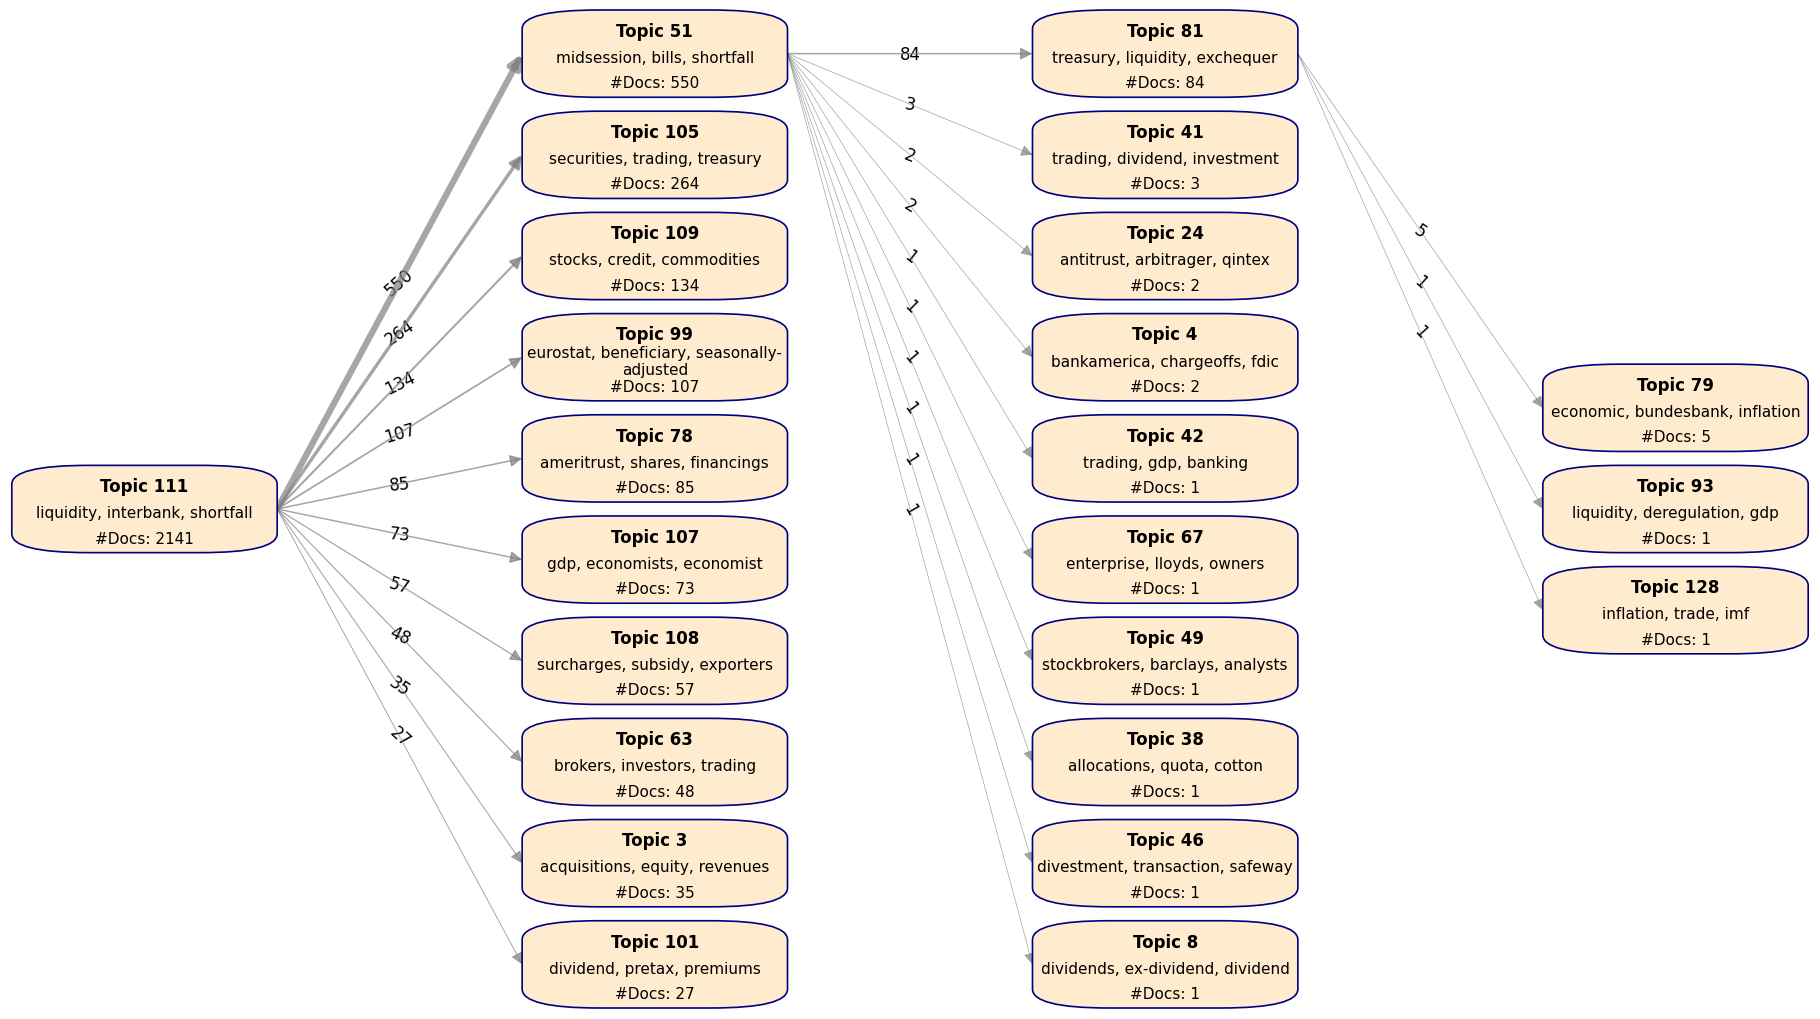

In [37]:
display_ranked_topic_graph(start_topic_id=111, n_words=3)

In [38]:
# 18253
show_document_with_topics(1170)

Document ID: 1170
The U.S. Treasury repeated a White House statement that only President Reagan and Treasury Secretary James Baker are authorized to speak on the dollar. A Department spokesman was commenting on remarks by Commerce Department Under-Secretary Robert Ortner that the yen was undervalued 10 or 15 pct against the dollar but European currencies were fairly priced against the U.S. currency. "As Larry Speakes said on January 14 this year, only two people in this administration are authorized to speak on the dollar and that is the president and the secretary of the treasury," the spokesman told Reuters.
Topics in this document:
  Topic 12: 0.015220004301615226
  Top words: undervalued, markets, macroeconomic, economic, trade, treasury, inflation, recession, monetary, commerce
  Topic 111: 0.015177626070188986
  Top words: liquidity, interbank, shortfall, market, bank, sterling, money, amounts, purchases, billion


In [39]:
def get_ordered_topics(doc):
    return [int(topic_id) for topic_id, prob in doc]


def format_topic_label(topic_id, topics_dict=None, n_words=3):
    if topics_dict is None:
        return f"Topic {topic_id}"

    words = topics_dict.get(int(topic_id), [])
    top_words = [word for word, prob in words[:n_words]]

    if top_words:
        return f"Topic {topic_id}\n" + ", ".join(top_words)

    return f"Topic {topic_id}"


def build_matching_docs_knowledge_graph(
    final_topics_for_all,
    selected_paths,
    topics_dict=None,
    n_words=3
):

    ordered_docs = [
        get_ordered_topics(doc)
        for doc in final_topics_for_all
    ]

    KG = nx.Graph()

    for path in selected_paths:
        path = tuple(int(t) for t in path)
        level = len(path)

        matching_doc_indices = [
            doc_idx for doc_idx, topics in enumerate(ordered_docs)
            if len(topics) >= level
            and tuple(topics[:level]) == path
        ]

        path_node = ("path", path)

        KG.add_node(
            path_node,
            node_type="path",
            label=" -> ".join(f"T{topic_id}" for topic_id in path),
            doc_count=len(matching_doc_indices)
        )

        for topic_rank, topic_id in enumerate(path, start=1):
            topic_node = ("topic", topic_id)

            KG.add_node(
                topic_node,
                node_type="topic",
                label=format_topic_label(topic_id, topics_dict, n_words)
            )

            KG.add_edge(
                path_node,
                topic_node,
                relation=f"rk {topic_rank}"
            )

        for doc_idx in matching_doc_indices:
            doc_node = ("doc", doc_idx)

            KG.add_node(
                doc_node,
                node_type="doc",
                label=f"Doc {doc_idx + 1}"
            )

            KG.add_edge(
                path_node,
                doc_node,
                relation="matches"
            )

    return KG

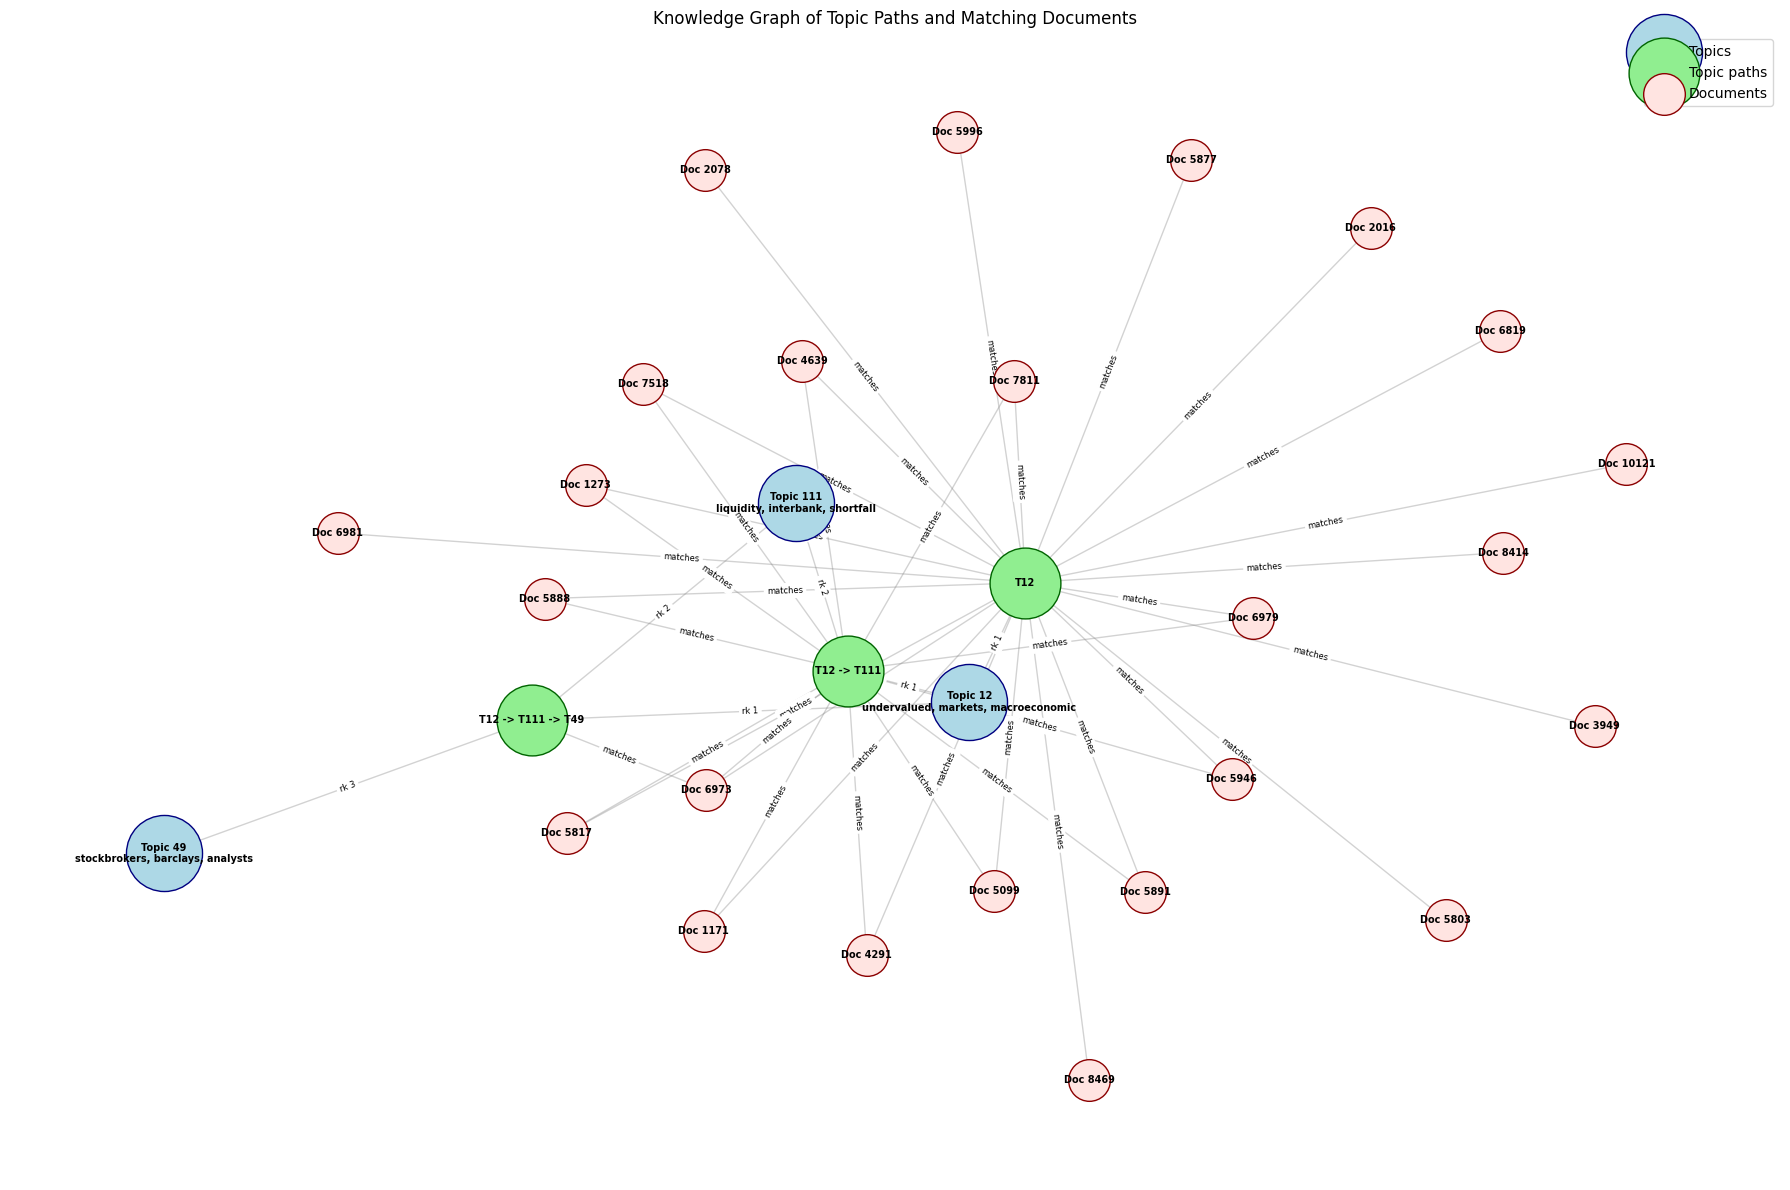

In [40]:
KG = build_matching_docs_knowledge_graph(
    final_topics_for_all=final_topics_for_all,
    selected_paths=[
        (12,),
        (12, 111),
        (12, 111, 49)
        #(10, 20, 53, 99)
    ],
    topics_dict=topics_dict,
    n_words=3
)

pos = nx.spring_layout(KG, seed=42, k=0.8)

node_types = nx.get_node_attributes(KG, "node_type")

topic_nodes = [node for node, t in node_types.items() if t == "topic"]
path_nodes = [node for node, t in node_types.items() if t == "path"]
doc_nodes = [node for node, t in node_types.items() if t == "doc"]

plt.figure(figsize=(18, 12))

nx.draw_networkx_edges(
    KG,
    pos,
    alpha=0.35,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=topic_nodes,
    node_color="lightblue",
    edgecolors="navy",
    node_size=3000,
    label="Topics"
)

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=path_nodes,
    node_color="lightgreen",
    edgecolors="darkgreen",
    node_size=2600,
    label="Topic paths"
)

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=doc_nodes,
    node_color="mistyrose",
    edgecolors="darkred",
    node_size=900,
    label="Documents"
)

labels = nx.get_node_attributes(KG, "label")

nx.draw_networkx_labels(
    KG,
    pos,
    labels=labels,
    font_size=7,
    font_weight="bold"
)

edge_labels = nx.get_edge_attributes(KG, "relation")

nx.draw_networkx_edge_labels(
    KG,
    pos,
    edge_labels=edge_labels,
    font_size=6
)

plt.title("Knowledge Graph of Topic Paths and Matching Documents")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

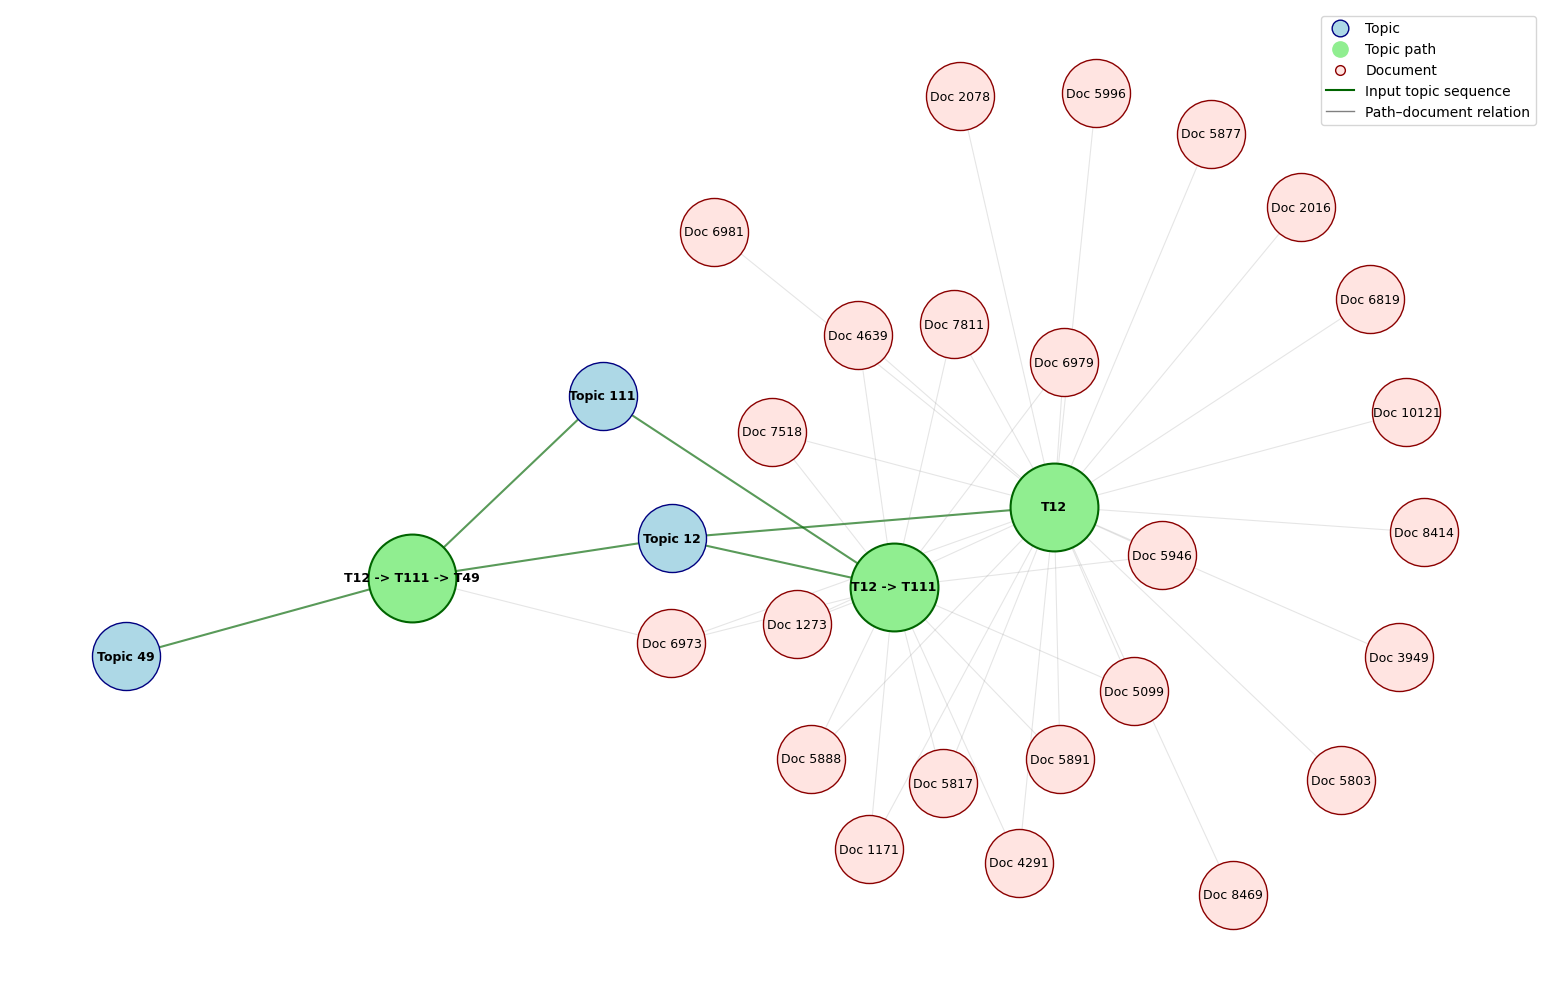

In [41]:
from matplotlib.lines import Line2D

KG = build_matching_docs_knowledge_graph(
    final_topics_for_all=final_topics_for_all,
    selected_paths=[
        (12,),
        (12, 111),
        (12, 111, 49)
    ],
    topics_dict=topics_dict,
    n_words=0
)

# --------------------------------------------------
# Node types
# --------------------------------------------------

node_types = nx.get_node_attributes(KG, "node_type")

topic_nodes = [
    node for node, t in node_types.items()
    if t == "topic"
]

path_nodes = [
    node for node, t in node_types.items()
    if t == "path"
]

doc_nodes = [
    node for node, t in node_types.items()
    if t == "doc"
]

# --------------------------------------------------
# Edge types, inferred from connected node types
# --------------------------------------------------

topic_path_edges = []
path_doc_edges = []
other_edges = []

for u, v in KG.edges():

    type_u = KG.nodes[u].get("node_type")
    type_v = KG.nodes[v].get("node_type")

    node_pair = {type_u, type_v}

    if node_pair == {"topic", "path"}:
        topic_path_edges.append((u, v))

    elif node_pair == {"path", "doc"}:
        path_doc_edges.append((u, v))

    else:
        other_edges.append((u, v))

# --------------------------------------------------
# Layout
# --------------------------------------------------

pos = nx.spring_layout(
    KG,
    seed=42,
    k=0.5
)

plt.figure(figsize=(16, 10))

# --------------------------------------------------
# Edges
# --------------------------------------------------

nx.draw_networkx_edges(
    KG,
    pos,
    edgelist=topic_path_edges,
    edge_color="darkgreen",
    alpha=0.65,
    width=1.5
)

nx.draw_networkx_edges(
    KG,
    pos,
    edgelist=path_doc_edges,
    edge_color="gray",
    alpha=0.20,
    width=0.8
)

if other_edges:
    nx.draw_networkx_edges(
        KG,
        pos,
        edgelist=other_edges,
        edge_color="lightgray",
        alpha=0.2,
        width=0.8
    )

# --------------------------------------------------
# Nodes
# --------------------------------------------------

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=topic_nodes,
    node_color="lightblue",
    edgecolors="navy",
    linewidths=1.0,
    node_size=2400
)

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=path_nodes,
    node_color="lightgreen",
    edgecolors="darkgreen",
    linewidths=1.5,
    node_size=4000
)

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=doc_nodes,
    node_color="mistyrose",
    edgecolors="darkred",
    linewidths=1.0,
    node_size=2400,
    #alpha=0.85
)
# --------------------------------------------------
# Labels: topics and paths
# --------------------------------------------------

main_nodes = topic_nodes + path_nodes

main_labels = {
    node: KG.nodes[node]["label"]
    for node in main_nodes
}

nx.draw_networkx_labels(
    KG,
    pos,
    labels=main_labels,
    font_size=9,
    font_weight="bold"
)

# --------------------------------------------------
# Labels: document IDs
# --------------------------------------------------

doc_labels = {
    node: KG.nodes[node]["label"]
    for node in doc_nodes
}

nx.draw_networkx_labels(
    KG,
    pos,
    labels=doc_labels,
    font_size=9,
    font_weight="normal"
)

# --------------------------------------------------
# Optional edge labels
# --------------------------------------------------

# I would normally omit these in the thesis figure,
# because they can make the graph very crowded.

# edge_labels = nx.get_edge_attributes(KG, "relation")
# nx.draw_networkx_edge_labels(
#     KG,
#     pos,
#     edge_labels=edge_labels,
#     font_size=6,
#     rotate=False
# )

# --------------------------------------------------
# Legend
# --------------------------------------------------

legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="lightblue",
        markeredgecolor="navy",
        markersize=12,
        label="Topic"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="lightgreen",
        markeredgecolor="lightgreen",
        markersize=11,
        label="Topic path"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="mistyrose",
        markeredgecolor="darkred",
        markersize=7,
        label="Document"
    ),
    Line2D(
        [0], [0],
        color="darkgreen",
        lw=1.5,
        label="Input topic sequence"
    ),
    Line2D(
        [0], [0],
        color="gray",
        lw=1,
        label="Path–document relation"
    )
]

plt.legend(
    handles=legend_elements,
    loc="upper left",
    bbox_to_anchor=(0.85, 1),
    frameon=True,
    fontsize=10
)

# plt.title(
#     "Knowledge Graph of Topic Paths and Matching Documents",
#     fontsize=14,
#     pad=15
# )

plt.axis("off")
plt.tight_layout()
plt.savefig(
        "graph_path.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0
    )
plt.show()

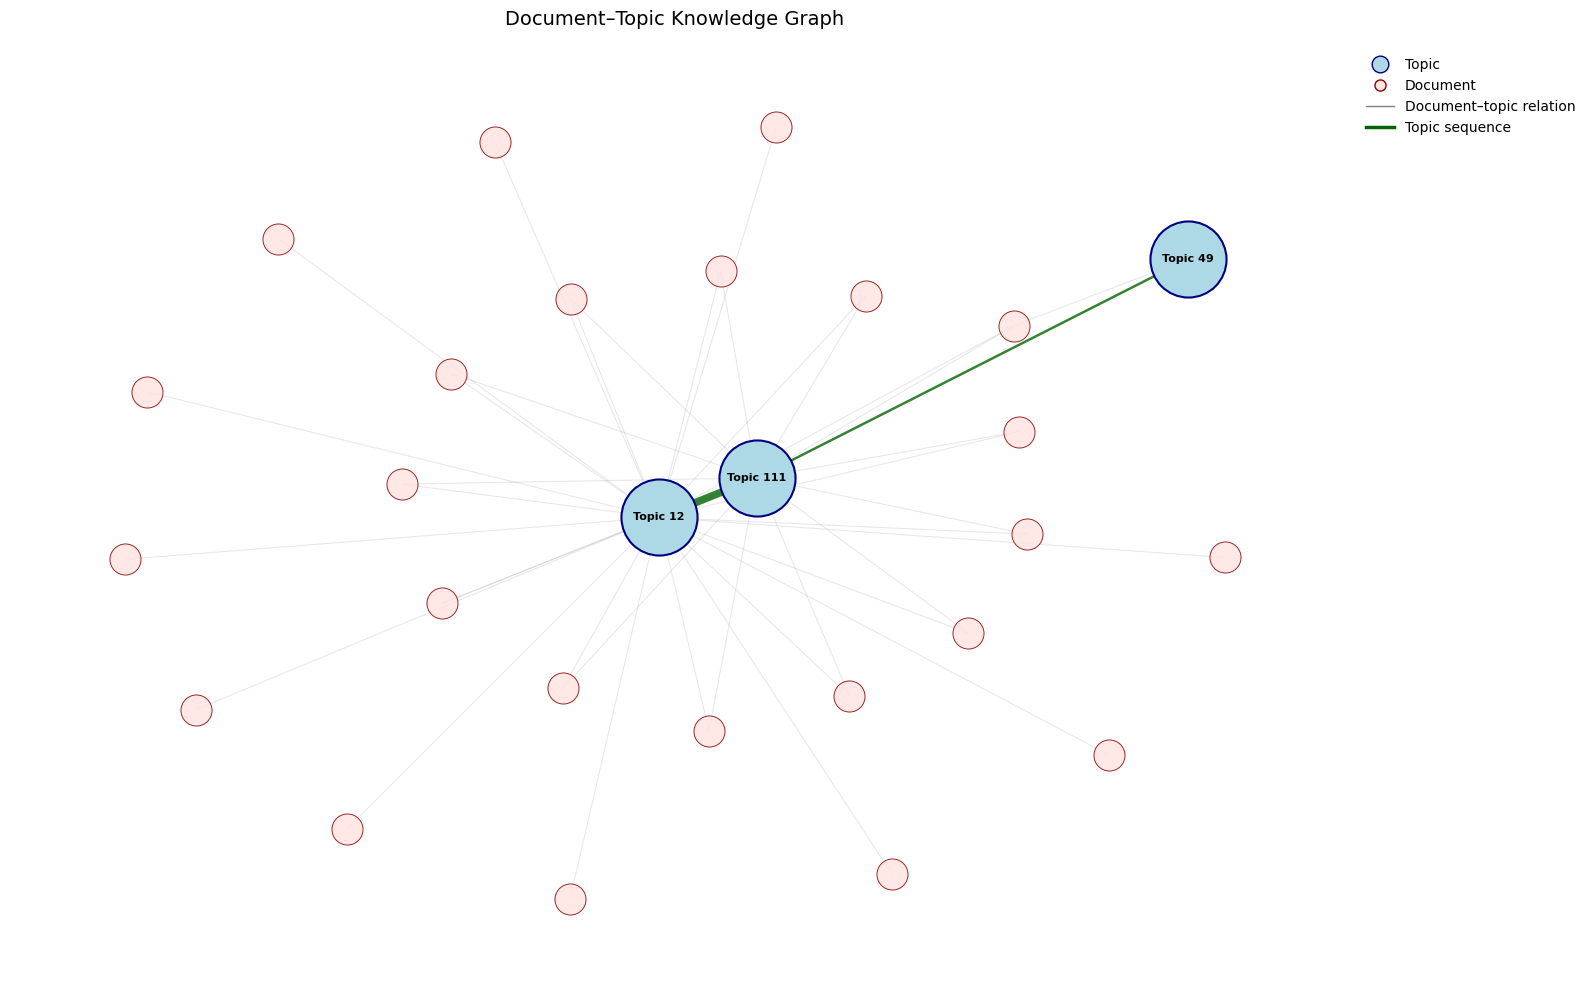

In [159]:
from matplotlib.lines import Line2D

KG = build_doc_topic_knowledge_graph(
    final_topics_for_all=final_topics_for_all,
    selected_paths=[
        (12,),
        (12, 111),
        (12, 111, 49)
    ],
    topics_dict=topics_dict,
    n_words=0,
    include_topic_sequence_edges=True
)

# ------------------------------------------
# Extract nodes and edges
# ------------------------------------------

node_types = nx.get_node_attributes(KG, "node_type")

topic_nodes = [
    node for node, node_type in node_types.items()
    if node_type == "topic"
]

doc_nodes = [
    node for node, node_type in node_types.items()
    if node_type == "doc"
]

edge_types = nx.get_edge_attributes(KG, "edge_type")

doc_topic_edges = [
    edge for edge, edge_type in edge_types.items()
    if edge_type == "doc_topic"
]

topic_sequence_edges = [
    edge for edge, edge_type in edge_types.items()
    if edge_type == "topic_sequence"
]

# ------------------------------------------
# Layout
# ------------------------------------------

pos = nx.spring_layout(
    KG,
    seed=42,
    k=0.6
)

plt.figure(figsize=(16, 10))

# ------------------------------------------
# Document-topic edges
# ------------------------------------------

nx.draw_networkx_edges(
    KG,
    pos,
    edgelist=doc_topic_edges,
    edge_color="gray",
    alpha=0.18,
    width=0.8
)

# ------------------------------------------
# Topic sequence edges
# ------------------------------------------

sequence_weights = {
    edge: KG.edges[edge]["weight"]
    for edge in topic_sequence_edges
}

if sequence_weights:
    max_weight = max(sequence_weights.values())

    sequence_edge_widths = [
        1.5 + 4 * sequence_weights[edge] / max_weight
        for edge in topic_sequence_edges
    ]
else:
    sequence_edge_widths = []

nx.draw_networkx_edges(
    KG,
    pos,
    edgelist=topic_sequence_edges,
    edge_color="darkgreen",
    alpha=0.8,
    width=sequence_edge_widths
)

# ------------------------------------------
# Nodes
# ------------------------------------------

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=topic_nodes,
    node_color="lightblue",
    edgecolors="navy",
    linewidths=1.5,
    node_size=3000
)

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=doc_nodes,
    node_color="mistyrose",
    edgecolors="darkred",
    linewidths=0.7,
    node_size=500,
    alpha=0.85
)

# ------------------------------------------
# Only topic labels
# ------------------------------------------

topic_labels = {
    node: KG.nodes[node]["label"]
    for node in topic_nodes
}

nx.draw_networkx_labels(
    KG,
    pos,
    labels=topic_labels,
    font_size=8,
    font_weight="bold"
)

# ------------------------------------------
# Legend
# ------------------------------------------

legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="lightblue",
        markeredgecolor="navy",
        markersize=12,
        label="Topic"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="mistyrose",
        markeredgecolor="darkred",
        markersize=8,
        label="Document"
    ),
    Line2D(
        [0], [0],
        color="gray",
        lw=1,
        label="Document–topic relation"
    ),
    Line2D(
        [0], [0],
        color="darkgreen",
        lw=2.5,
        label="Topic sequence"
    )
]

plt.legend(
    handles=legend_elements,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False,
    fontsize=10
)

plt.title(
    "Document–Topic Knowledge Graph",
    fontsize=14,
    pad=15
)

plt.axis("off")
plt.tight_layout()
plt.show()

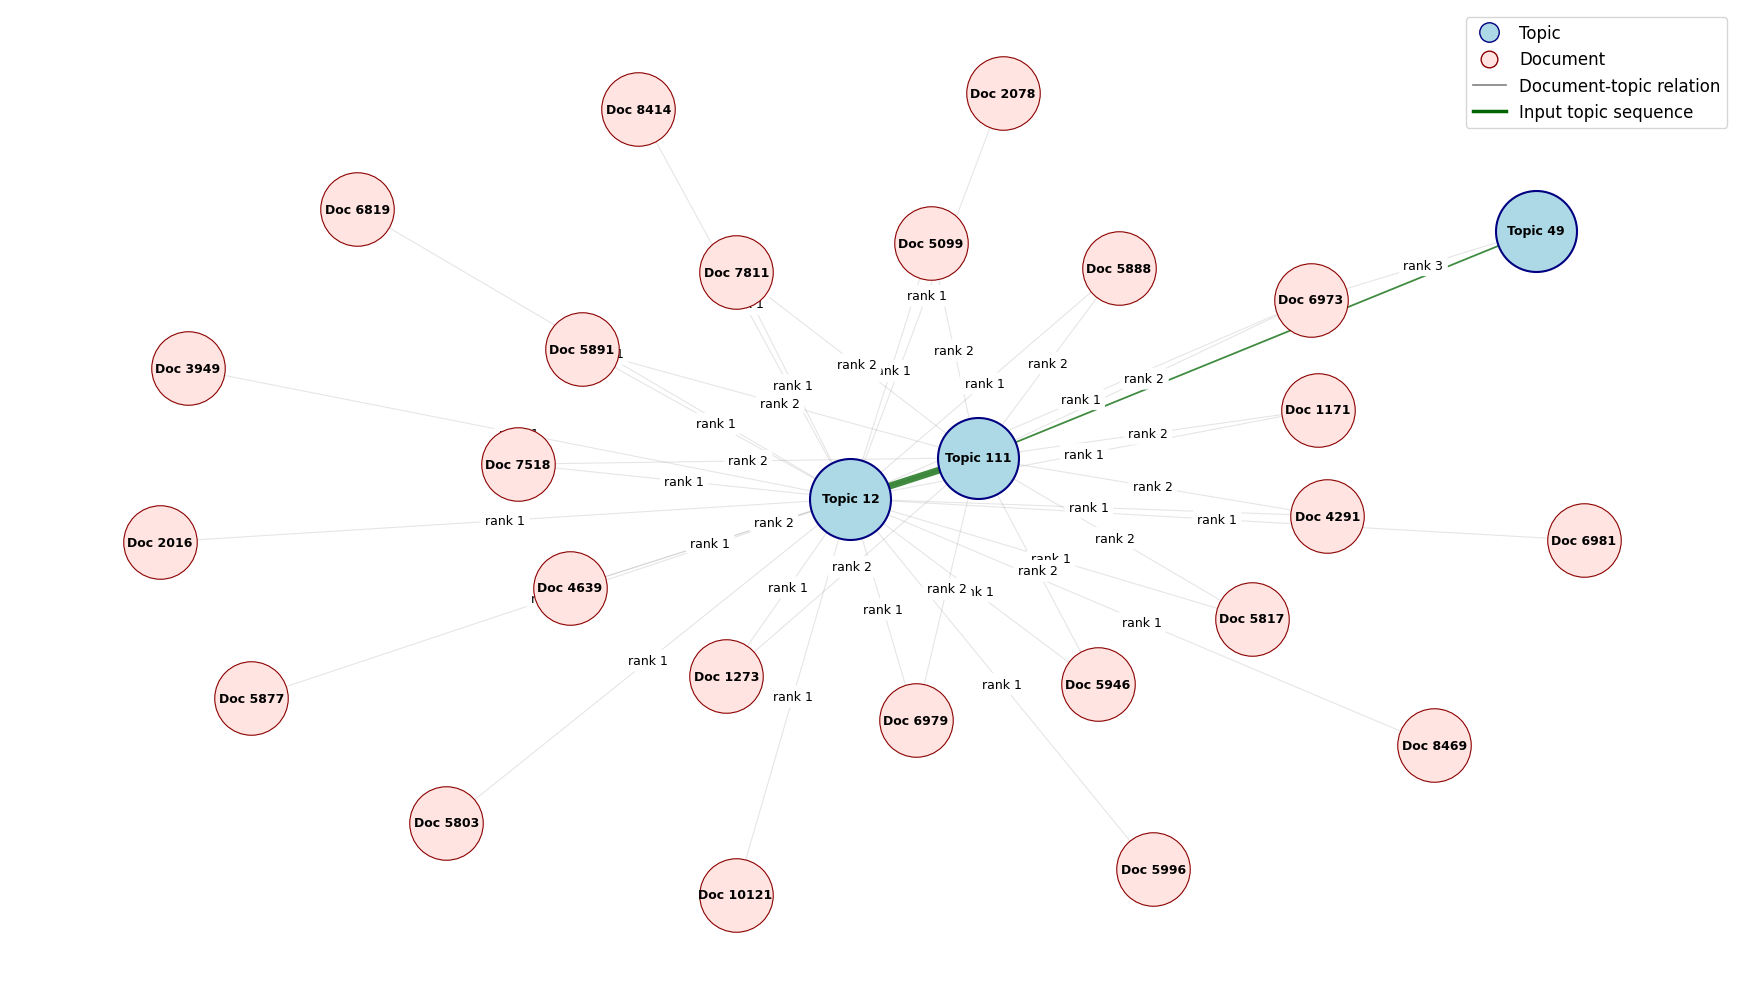

In [160]:
from matplotlib.lines import Line2D

plt.figure(figsize=(18, 10))

# -----------------------------
# Edges: document-topic
# -----------------------------
nx.draw_networkx_edges(
    KG,
    pos,
    edgelist=doc_topic_edges,
    alpha=0.20,
    edge_color="gray",
    width=0.8
)

# -----------------------------
# Edges: topic sequence
# -----------------------------
sequence_weights = nx.get_edge_attributes(KG, "weight")

sequence_edge_widths = [
    1 + 4 * sequence_weights[edge] / max(sequence_weights.values())
    for edge in topic_sequence_edges
] if topic_sequence_edges else []

nx.draw_networkx_edges(
    KG,
    pos,
    edgelist=topic_sequence_edges,
    alpha=0.75,
    edge_color="darkgreen",
    width=sequence_edge_widths
)

# -----------------------------
# Nodes
# -----------------------------
nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=topic_nodes,
    node_color="lightblue",
    edgecolors="navy",
    linewidths=1.5,
    node_size=3400
)

nx.draw_networkx_nodes(
    KG,
    pos,
    nodelist=doc_nodes,
    node_color="mistyrose",
    edgecolors="darkred",
    linewidths=0.8,
    node_size=2800
)

# -----------------------------
# Labels
# -----------------------------
labels = nx.get_node_attributes(KG, "label")

nx.draw_networkx_labels(
    KG,
    pos,
    labels=labels,
    font_size=9,
    font_weight="bold"
)

# -----------------------------
# Document-topic edge labels
# -----------------------------
doc_topic_edge_labels = {
    edge: KG.edges[edge]["relation"]
    for edge in doc_topic_edges
}

nx.draw_networkx_edge_labels(
    KG,
    pos,
    edge_labels=doc_topic_edge_labels,
    font_size=9,
    rotate=False
)

# -----------------------------
# Custom legend
# -----------------------------
legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="Topic",
        markerfacecolor="lightblue",
        markeredgecolor="navy",
        markersize=14
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="Document",
        markerfacecolor="mistyrose",
        markeredgecolor="darkred",
        markersize=12
    ),
    Line2D(
        [0], [0],
        color="gray",
        lw=1.2,
        label="Document-topic relation"
    ),
    Line2D(
        [0], [0],
        color="darkgreen",
        lw=2.5,
        label="Input topic sequence"
    )
]

plt.legend(
    handles=legend_elements,
    loc="upper left",
    bbox_to_anchor=(0.84, 1),
    frameon=True,
    fontsize=12
)

# plt.title(
#     "Document–Topic Knowledge Graph",
#     fontsize=15,
#     pad=15
# )

plt.axis("off")
plt.tight_layout()
plt.savefig(
        "graph_doc_topic.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0
    )

plt.show()

In [117]:
topic_id = 12

count_anywhere = sum(
    any(int(t) == topic_id for t, prob in doc)
    for doc in final_topics_for_all
)

count_rank1 = sum(
    len(doc) > 0 and int(doc[0][0]) == topic_id
    for doc in final_topics_for_all
)

print("Topic 12 anywhere:", count_anywhere)
print("Topic 12 at rank 1:", count_rank1)

Topic 12 anywhere: 51
Topic 12 at rank 1: 24


In [42]:
# import matplotlib.pyplot as plt
# import networkx as nx

# from matplotlib.lines import Line2D
# from matplotlib.patches import Patch


# # ------------------------------------------
# # 1. Layout
# # ------------------------------------------

# pos = nx.spring_layout(
#     KG,
#     seed=42,
#     k=1.15,
#     iterations=200
# )

# node_types = nx.get_node_attributes(KG, "node_type")
# edge_types = nx.get_edge_attributes(KG, "edge_type")

# topic_nodes = [
#     node for node, node_type in node_types.items()
#     if node_type == "topic"
# ]

# doc_nodes = [
#     node for node, node_type in node_types.items()
#     if node_type == "doc"
# ]

# doc_topic_edges = [
#     edge for edge, edge_type in edge_types.items()
#     if edge_type == "doc_topic"
# ]

# topic_sequence_edges = [
#     edge for edge, edge_type in edge_types.items()
#     if edge_type == "topic_sequence"
# ]


# # ------------------------------------------
# # 2. Figure
# # ------------------------------------------

# fig, ax = plt.subplots(figsize=(18, 12))


# # ------------------------------------------
# # 3. Document-topic edges
# # ------------------------------------------

# nx.draw_networkx_edges(
#     KG,
#     pos,
#     edgelist=doc_topic_edges,
#     edge_color="#B0B0B0",
#     alpha=0.30,
#     width=0.8,
#     ax=ax
# )


# # ------------------------------------------
# # 4. Topic-sequence edges
# # ------------------------------------------

# sequence_weights = nx.get_edge_attributes(KG, "weight")

# if topic_sequence_edges:

#     max_weight = max(
#         sequence_weights.get(edge, 1)
#         for edge in topic_sequence_edges
#     )

#     sequence_edge_widths = [
#         1.5 + 4.0 * sequence_weights.get(edge, 1) / max_weight
#         for edge in topic_sequence_edges
#     ]

#     nx.draw_networkx_edges(
#         KG,
#         pos,
#         edgelist=topic_sequence_edges,
#         edge_color="#357A38",
#         alpha=0.80,
#         width=sequence_edge_widths,
#         ax=ax
#     )


# # ------------------------------------------
# # 5. Document nodes
# # ------------------------------------------

# nx.draw_networkx_nodes(
#     KG,
#     pos,
#     nodelist=doc_nodes,
#     node_shape="o",
#     node_size=430,
#     node_color="#F6DADA",
#     edgecolors="#A94442",
#     linewidths=1.0,
#     ax=ax
# )


# # ------------------------------------------
# # 6. Topic nodes
# # ------------------------------------------
# # Instead of drawing large circular nodes,
# # draw the topic labels as rounded boxes,
# # similarly to the flow-based graphs.

# labels = nx.get_node_attributes(KG, "label")

# for node in topic_nodes:

#     x, y = pos[node]

#     ax.text(
#         x,
#         y,
#         labels[node],
#         ha="center",
#         va="center",
#         fontsize=8,
#         fontweight="bold",
#         bbox=dict(
#             boxstyle="round,pad=0.45",
#             facecolor="#DCEAF7",
#             edgecolor="#2F5597",
#             linewidth=1.4
#         ),
#         zorder=5
#     )


# # ------------------------------------------
# # 7. Document labels
# # ------------------------------------------

# doc_labels = {
#     node: labels[node]
#     for node in doc_nodes
# }

# nx.draw_networkx_labels(
#     KG,
#     pos,
#     labels=doc_labels,
#     font_size=6.5,
#     font_weight="bold",
#     ax=ax
# )


# # ------------------------------------------
# # 8. Edge labels
# # ------------------------------------------

# doc_topic_edge_labels = {
#     edge: KG.edges[edge]["relation"]
#     for edge in doc_topic_edges
# }

# nx.draw_networkx_edge_labels(
#     KG,
#     pos,
#     edge_labels=doc_topic_edge_labels,
#     font_size=5.5,
#     font_color="#555555",
#     rotate=False,
#     bbox=dict(
#         facecolor="white",
#         edgecolor="none",
#         alpha=0.65,
#         pad=0.2
#     ),
#     ax=ax
# )


# # ------------------------------------------
# # 9. Custom legend
# # ------------------------------------------

# legend_elements = [

#     Patch(
#         facecolor="#DCEAF7",
#         edgecolor="#2F5597",
#         linewidth=1.4,
#         label="Topic"
#     ),

#     Line2D(
#         [0], [0],
#         marker="o",
#         color="none",
#         markerfacecolor="#F6DADA",
#         markeredgecolor="#A94442",
#         markeredgewidth=1.0,
#         markersize=8,
#         label="Document"
#     ),

#     Line2D(
#         [0], [0],
#         color="#B0B0B0",
#         linewidth=1.2,
#         alpha=0.7,
#         label="Document–Topic relation"
#     ),

#     Line2D(
#         [0], [0],
#         color="#357A38",
#         linewidth=3,
#         label="Topic sequence"
#     )
# ]

# ax.legend(
#     handles=legend_elements,
#     loc="upper left",
#     frameon=True,
#     framealpha=0.95,
#     fontsize=9
# )


# # ------------------------------------------
# # 10. Final formatting
# # ------------------------------------------

# # ax.set_title(
# #     "Document–Topic Knowledge Graph",
# #     fontsize=15,
# #     pad=18
# # )

# ax.axis("off")

# plt.tight_layout()
# plt.show()

In [ ]:

from sklearn.manifold import MDS
from sklearn.metrics.pairwise import cosine_distances

# 2. Transform data into a Document-Topic Matrix (DataFrame)
# Find all unique topics
all_topics = set()
for doc in final_topics_for_all:
    for topic_id, _ in doc:
        all_topics.add(int(topic_id))
        
all_topics = sorted(list(all_topics))

# Build a matrix filled with zeros
matrix_data = np.zeros((len(final_topics_for_all), len(all_topics)))
df = pd.DataFrame(matrix_data, columns=[f"Topic {t}" for t in all_topics], 
                  index=[f"Doc {i+1}" for i in range(len(final_topics_for_all))])

# Populate the matrix with probabilities
for doc_idx, doc in enumerate(final_topics_for_all):
    for topic_id, prob in doc:
        df.at[f"Doc {doc_idx+1}", f"Topic {int(topic_id)}"] = float(prob)


In [ ]:
topic_doc_df = df.T
topic_doc_df

,Doc 1,Doc 2,Doc 3,Doc 4,Doc 5,Doc 6,Doc 7,Doc 8,Doc 9,Doc 10,...,Doc 337730,Doc 337731,Doc 337732,Doc 337733,Doc 337734,Doc 337735,Doc 337736,Doc 337737,Doc 337738,Doc 337739
Topic 0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Topic 1,0.0,0.0,0.0,0.0,0.0,0.0,0.723857,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Topic 2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Topic 3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Topic 4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Topic 495,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Topic 496,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Topic 497,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Topic 498,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
topics_to_plot = ["Topic 0", "Topic 32", "Topic 15", "Topic 6"]
filtered_topic_df = topic_doc_df.loc[topics_to_plot]

#filtered_topic_df = topic_doc_df

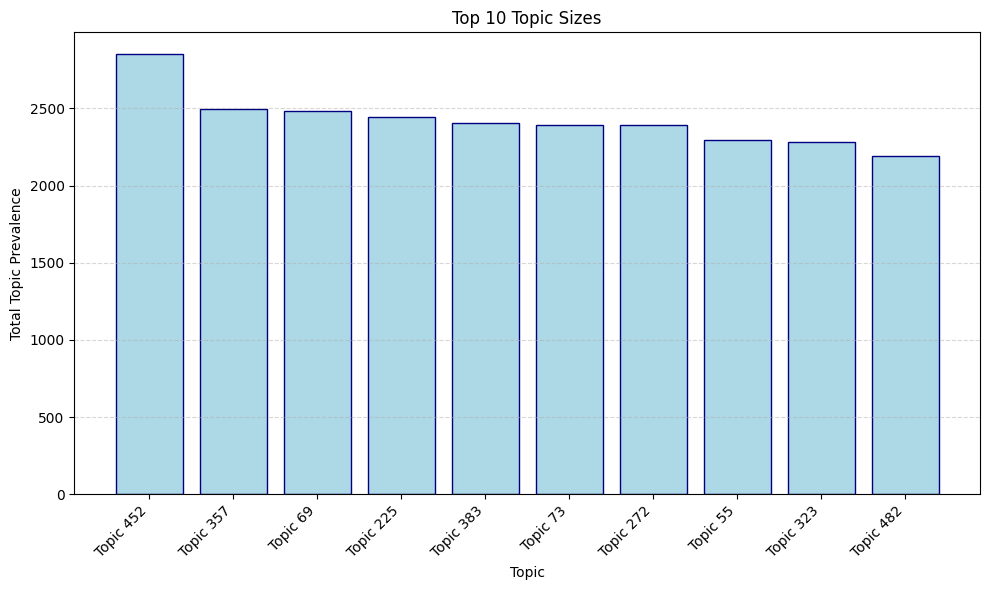

In [ ]:
# Total prevalence of each topic across all documents
tot_topic_sizes = topic_doc_df.sum(axis=1)

# Select top 10 topics by size
top_10_topic_sizes = tot_topic_sizes.sort_values(ascending=False).head(10)

# Plot
plt.figure(figsize=(10, 6))
plt.bar(top_10_topic_sizes.index, top_10_topic_sizes.values, color="lightblue", edgecolor="navy")

plt.title("Top 10 Topic Sizes")
plt.xlabel("Topic")
plt.ylabel("Total Topic Prevalence")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate cosine distances between topics based on their document distribution
# Topics that appear in the same documents with similar probabilities will be closer (distance near 0)
distances = cosine_distances(filtered_topic_df.values)

# Use multidimensional scaling to reduce these distances into 2D (X, Y) coordinates
# Similar topics will be closer together in the 2D space
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=42)
pos = mds.fit_transform(distances)

# Calculate topic prevalence (total sum of probabilities) to determine bubble size
# Sum of each topic probability across all documents
topic_sizes = filtered_topic_df.sum(axis=1).values

topic_sizes

d:\Projects\Thesis\PolyTopic\.venv\Lib\site-packages\sklearn\manifold\_mds.py:677: FutureWarning:

The default value of `n_init` will change from 4 to 1 in 1.9.



array([ 34.535452  , 235.26454542, 328.35938031,   5.6183866 ])

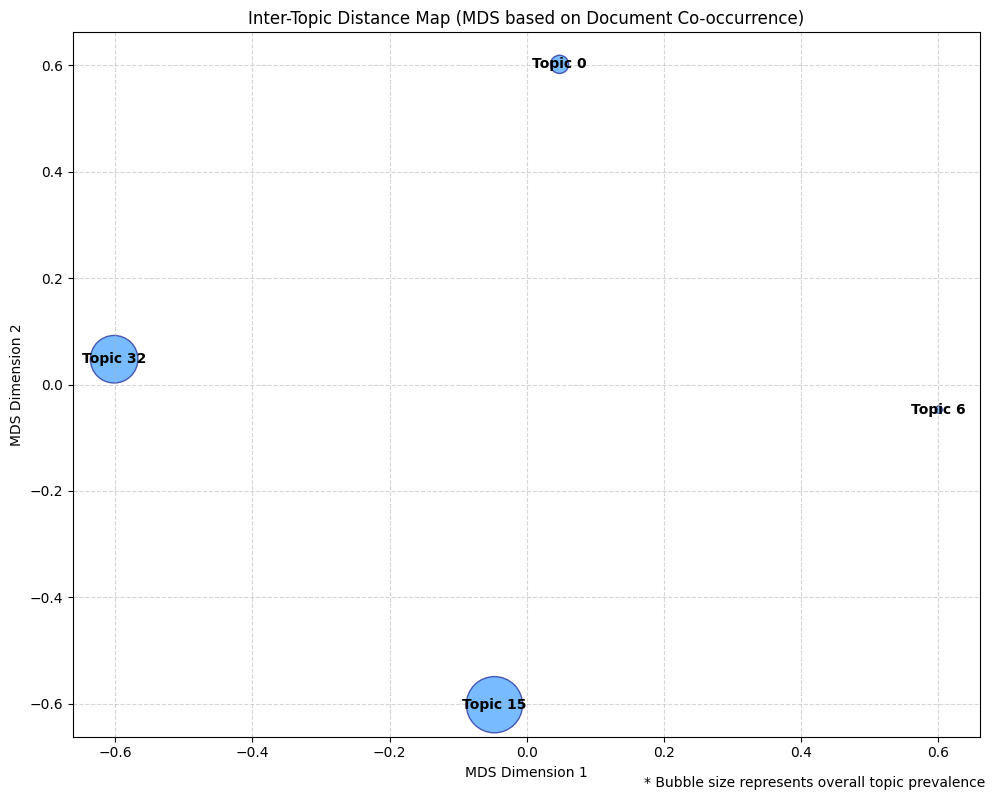

In [ ]:
plt.figure(figsize=(10, 8))
# Plot: x = first MDS dimension, y = second MDS dimension, size = topic prevalence
topic_size_scaling = 5 # Multiplier for visual scaling
plt.scatter(pos[:, 0], pos[:, 1], s=topic_sizes*topic_size_scaling, alpha=0.6, c='dodgerblue', edgecolors='navy')

# Add labels to the bubbles
for i, topic_name in enumerate(filtered_topic_df.index):
    plt.annotate(topic_name, 
                 (pos[i, 0], pos[i, 1]), 
                 ha='center', va='center', 
                 fontsize=10, fontweight='bold')

plt.title("Inter-Topic Distance Map (MDS based on Document Co-occurrence)")
plt.xlabel("MDS Dimension 1")
plt.ylabel("MDS Dimension 2")
plt.grid(True, linestyle='--', alpha=0.5)

# Add a legend for bubble size explanation
plt.figtext(0.99, 0.01, '* Bubble size represents overall topic prevalence', horizontalalignment='right')

plt.tight_layout()
plt.show()